# Classical Forecasting: Baselines, ETS, and (S)ARIMA

**What you'll learn**

- Why every forecasting project starts with **naive, seasonal-naive, and drift baselines**
  — they set the bar, and on many business series they are embarrassingly hard to beat.
- **ETS / Holt-Winters** as a component model: additive vs multiplicative seasonality
  (and how to tell which one your series needs), damped trends, and how to *read* the
  fitted level/trend/season components and smoothing parameters.
- **SARIMA** with pragmatic order selection: read the ACF/PACF for candidates, then let a
  small AICc grid arbitrate — plus residual diagnostics (Ljung-Box, residual ACF) that
  tell you whether the model actually captured the dynamics.
- **Prediction intervals** that widen with horizon (fan charts), and an *empirical
  coverage check* via backtest: nominal 95% intervals frequently cover less than 95% on
  real-ish data — we demonstrate exactly this, and why.
- **Rolling-origin evaluation** implemented properly, comparing all models on MAE, RMSE,
  MAPE, sMAPE, MASE — and the metric pathologies (MAPE explodes near zero and rewards
  under-forecasting; MASE is the sane default).
- Where **Prophet-style decomposable models** fit in the landscape (concept only, no
  dependency).

**Why it matters in interviews**

- "How would you forecast X, and how would you know it's any good?" is the standard
  opener for any forecasting-adjacent role. The senior answer is baselines + rolling
  origin + scale-free metrics + interval calibration, not a model name.
- "ETS vs ARIMA — when would you use each?" and "why is MAPE a bad default?" are
  classic screens for whether you've actually shipped forecasts.
- "Your 95% intervals only cover 80% in production — why?" separates people who have
  validated intervals from people who have only ever plotted them.

Prerequisites: decomposition, stationarity, and autocorrelation from notebook 01 in this
folder (time-series foundations). ML-based forecasting with gradient boosting and global
models — where you go when you have thousands of related series — is covered in the ML
forecasting notebook in this folder; this notebook builds the classical toolkit those
models must beat.

In [1]:
import itertools
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tools.sm_exceptions import ConvergenceWarning
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.stattools import adfuller, kpss

rng = np.random.default_rng(42)

# The SARIMA grid below deliberately includes over-parameterized candidates; some fail to
# converge or start at non-invertible values. We record convergence status explicitly in
# the grid table instead of letting per-fit warnings spam the notebook.
warnings.filterwarnings("ignore", category=ConvergenceWarning)
warnings.filterwarnings("ignore", message="Non-invertible starting")
warnings.filterwarnings("ignore", message="Non-stationary starting")

plt.rcParams.update({
    "figure.figsize": (9.0, 4.2),
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.autolayout": True,
})
pd.set_option("display.precision", 4)

## 1. Two simulated series with known ground truth

Per the lab's data policy we simulate, so every claim below can be checked against the
generating process:

- **`air`** — a monthly airline-passengers-style series: a stochastic level with a
  slowly wandering growth rate (~5%/yr on average), **multiplicative** seasonality
  (summer peaks scale with the level) that itself drifts a little year to year, small
  multiplicative noise. This is the friendly textbook regime — but with genuinely
  evolving components, like real data, so differencing/smoothing has a real job to do.
- **`retail`** — monthly units shipped for a retail category: growth that flattens,
  **additive** seasonality with a Nov–Dec spike, random promo spikes (~10% of months),
  substantial noise, and a **demand acceleration late in the series** (t ≥ 124) — the
  kind of structural change real data inflicts on you. This is the honest regime.

Twelve years of monthly data (n=144). The last two years are held out in the narrative
sections; the backtest later uses rolling origins over the final year.

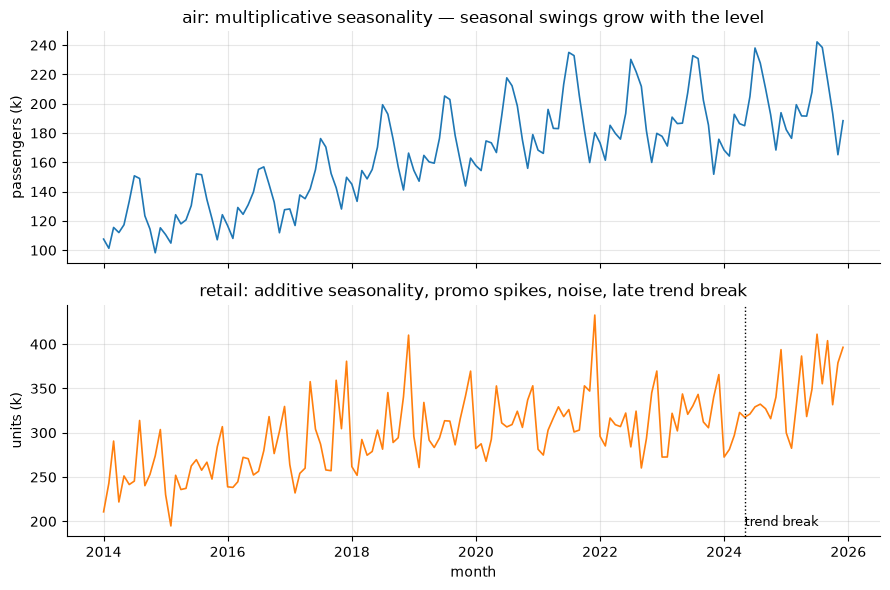

In [2]:
n = 144
months = pd.date_range("2014-01-01", periods=n, freq="MS")
t = np.arange(n)

# airline-style: multiplicative structure with stochastic level, growth and seasonality
seas_mult = np.array([0.90, 0.86, 0.98, 0.96, 0.98, 1.10,
                      1.22, 1.20, 1.06, 0.96, 0.84, 0.94])   # mean exactly 1
growth = 0.0045 + np.cumsum(rng.normal(0, 0.0006, n))        # wandering growth rate
log_level = np.log(120) + np.cumsum(growth + rng.normal(0, 0.012, n))
seas_log = np.zeros((12, 12))                                # yearly-drifting log factors
seas_log[0] = np.log(seas_mult)
for y in range(1, 12):
    seas_log[y] = seas_log[y - 1] + rng.normal(0, 0.006, 12)
    seas_log[y] -= seas_log[y].mean()                        # keep factors normalized
air = pd.Series(np.exp(log_level + seas_log[t // 12, t % 12] + rng.normal(0, 0.015, n)),
                index=months, name="passengers_k")

# retail-style: additive structure, promos, late trend break
seas_add = np.array([-24, -30, -8, -4, 2, 8, 12, 9, -3, 5, 28, 52], dtype=float)
base = 230 + 95 * (1 - np.exp(-t / 55))                  # growth that flattens
kink = np.where(t >= 124, 1.6 * (t - 124), 0.0)          # late demand acceleration
promo = (rng.random(n) < 0.10) * np.clip(rng.normal(55, 15, n), 0, None)
retail = pd.Series(base + kink + seas_add[t % 12] + promo + rng.normal(0, 13, n),
                   index=months, name="units_k")

TEST_H = 24
air_train, air_test = air.iloc[:-TEST_H], air.iloc[-TEST_H:]
ret_train, ret_test = retail.iloc[:-TEST_H], retail.iloc[-TEST_H:]

fig, axes = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
axes[0].plot(air, lw=1.2)
axes[0].set_title("air: multiplicative seasonality — seasonal swings grow with the level")
axes[0].set_ylabel("passengers (k)")
axes[1].plot(retail, lw=1.2, color="tab:orange")
axes[1].axvline(months[124], color="k", ls=":", lw=1)
axes[1].annotate("trend break", (months[124], retail.min()), fontsize=9)
axes[1].set_title("retail: additive seasonality, promo spikes, noise, late trend break")
axes[1].set_ylabel("units (k)")
axes[1].set_xlabel("month")
plt.show()

The visual diagnostic that decides additive vs multiplicative: do the seasonal swings
**grow with the level** (multiplicative — `air`) or stay **constant in absolute terms**
(additive — `retail`)? Multiplicative structure also means a **log transform** turns the
series into an additive one — which is exactly how we'll feed it to SARIMA later.

## 2. Baselines first, always

Three baselines cost five lines each and define the bar:

| Baseline | Forecast for $y_{T+h}$ | When it's strong |
|---|---|---|
| **naive** | $y_T$ | random-walk-like series (many financial/ops series) |
| **seasonal naive** | $y_{T+h-m}$ (same month last year) | strongly seasonal series |
| **drift** | $y_T + h\,\frac{y_T - y_1}{T-1}$ | trending series |

If your fancy model doesn't beat these *out of sample, with a margin that pays for its
complexity*, ship the baseline. Seasonal naive in particular is the canonical benchmark:
it is the denominator of MASE and the reference model in the M-competitions.

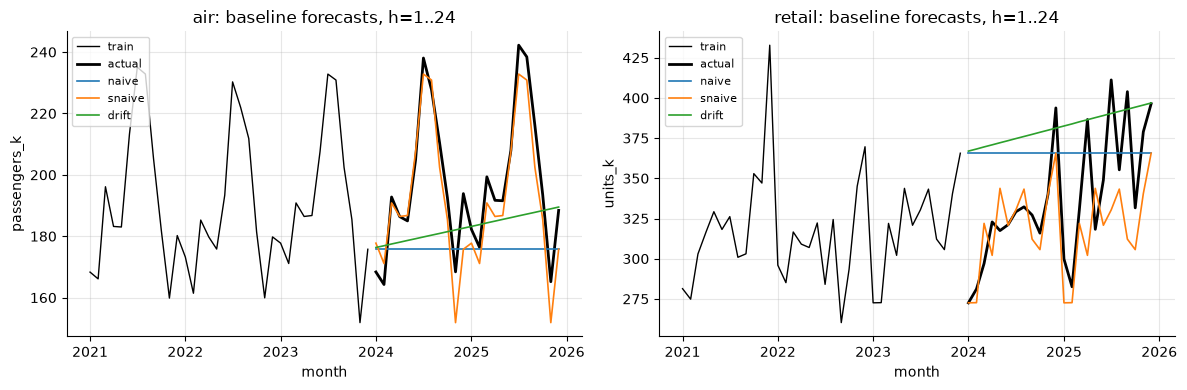

air     holdout MAE — naive:  24.21  snaive:   7.25  drift:  19.60
retail  holdout MAE — naive:  43.10  snaive:  25.43  drift:  48.32


In [3]:
def naive_fc(train: np.ndarray, h: int) -> np.ndarray:
    return np.repeat(train[-1], h)

def snaive_fc(train: np.ndarray, h: int, m: int = 12) -> np.ndarray:
    return np.tile(train[-m:], int(np.ceil(h / m)))[:h]

def drift_fc(train: np.ndarray, h: int) -> np.ndarray:
    slope = (train[-1] - train[0]) / (len(train) - 1)
    return train[-1] + slope * np.arange(1, h + 1)

BASELINES = {"naive": naive_fc, "snaive": snaive_fc, "drift": drift_fc}

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (name, tr, te) in zip(
        axes, [("air", air_train, air_test), ("retail", ret_train, ret_test)]):
    ax.plot(tr.iloc[-36:], color="k", lw=1, label="train")
    ax.plot(te, color="k", lw=2, label="actual")
    for bname, fn in BASELINES.items():
        ax.plot(te.index, fn(tr.to_numpy(), TEST_H), lw=1.2, label=bname)
    ax.set_title(f"{name}: baseline forecasts, h=1..{TEST_H}")
    ax.set_xlabel("month"); ax.set_ylabel(tr.name)
    ax.legend(fontsize=8)
plt.show()

for name, tr, te in [("air", air_train, air_test), ("retail", ret_train, ret_test)]:
    maes = {b: np.mean(np.abs(fn(tr.to_numpy(), TEST_H) - te.to_numpy()))
            for b, fn in BASELINES.items()}
    print(f"{name:7s} holdout MAE — " +
          "  ".join(f"{b}: {v:6.2f}" for b, v in maes.items()))

Seasonal naive is already respectable on both series — naive and drift are blind to
seasonality and it shows. Everything below is judged against `snaive`. (This single
holdout is only illustrative; Section 6 does the evaluation properly with rolling
origins.)

## 3. ETS / Holt-Winters: forecasting by explicit components

ETS models maintain smoothed **E**rror/**T**rend/**S**easonal components updated
recursively: a level $\ell_t$, a trend $b_t$, and seasonal states $s_t$, each with its
own smoothing parameter ($\alpha, \beta, \gamma$). The taxonomy is written
ETS(error, trend, seasonal), e.g. ETS(M,A,M) = multiplicative error, additive trend,
multiplicative seasonality — classic multiplicative Holt-Winters.

Two modeling decisions matter most in practice:

1. **Additive vs multiplicative seasonality** — get this wrong and residual variance is
   level-dependent, which wrecks both point forecasts and intervals.
2. **Damped trend** — an undamped additive trend extrapolates *linearly forever*.
   Business growth flattens; a damping factor $\phi < 1$ makes the trend contribution
   decay geometrically, and empirically (M3/M4 competitions) damping is one of the most
   reliable accuracy improvements in all of classical forecasting.

seasonal=additive         AICc=    415.8   holdout RMSE=   3.97
seasonal=multiplicative   AICc=    350.2   holdout RMSE=   5.00


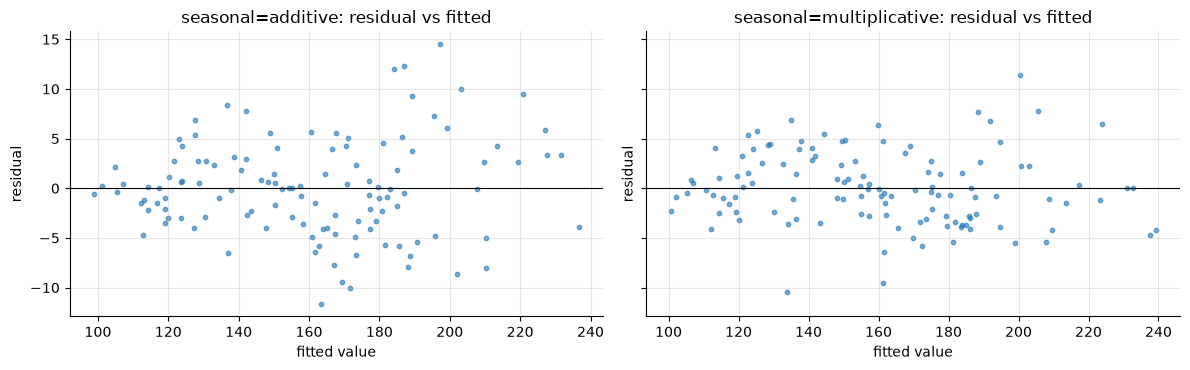

In [4]:
# Additive vs multiplicative seasonality on the airline series: fit both, compare.
hw_add = ExponentialSmoothing(air_train, trend="add", seasonal="add",
                              seasonal_periods=12,
                              initialization_method="estimated").fit()
hw_mul = ExponentialSmoothing(air_train, trend="add", seasonal="mul",
                              seasonal_periods=12,
                              initialization_method="estimated").fit()

for label, res in [("additive", hw_add), ("multiplicative", hw_mul)]:
    hold_rmse = np.sqrt(np.mean((res.forecast(TEST_H) - air_test) ** 2))
    print(f"seasonal={label:15s}  AICc={res.aicc:9.1f}   holdout RMSE={hold_rmse:7.2f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, (label, res) in zip(axes, [("additive", hw_add), ("multiplicative", hw_mul)]):
    ax.scatter(res.fittedvalues, res.resid, s=10, alpha=0.6)
    ax.axhline(0, color="k", lw=0.8)
    ax.set_title(f"seasonal={label}: residual vs fitted")
    ax.set_xlabel("fitted value"); ax.set_ylabel("residual")
plt.show()

The additive fit's residuals **fan out** as the level grows — the model forces constant
absolute seasonal swings onto a series whose swings are proportional. The multiplicative
fit's residuals are homoscedastic and its AICc is decisively lower (both models are fit
to the same untransformed data, so their likelihoods *are* comparable). Notice the
single 24-month holdout RMSE happens to side with the additive model — one split is a
noisy judge (Pitfall 3 quantifies exactly this), which is why the *structural* choice
should rest on the residual scatter and the likelihood, and accuracy claims on a
multi-origin backtest. The residual-vs-fitted scatter is the diagnostic to remember: it
answers the additive/multiplicative question even when the raw plot is ambiguous.

Smoothing parameters (how fast each component reacts to new data):
  alpha (level)     = 0.510
  beta  (trend)     = 0.000
  gamma (seasonal)  = 0.000
  phi   (damping)   = 0.993


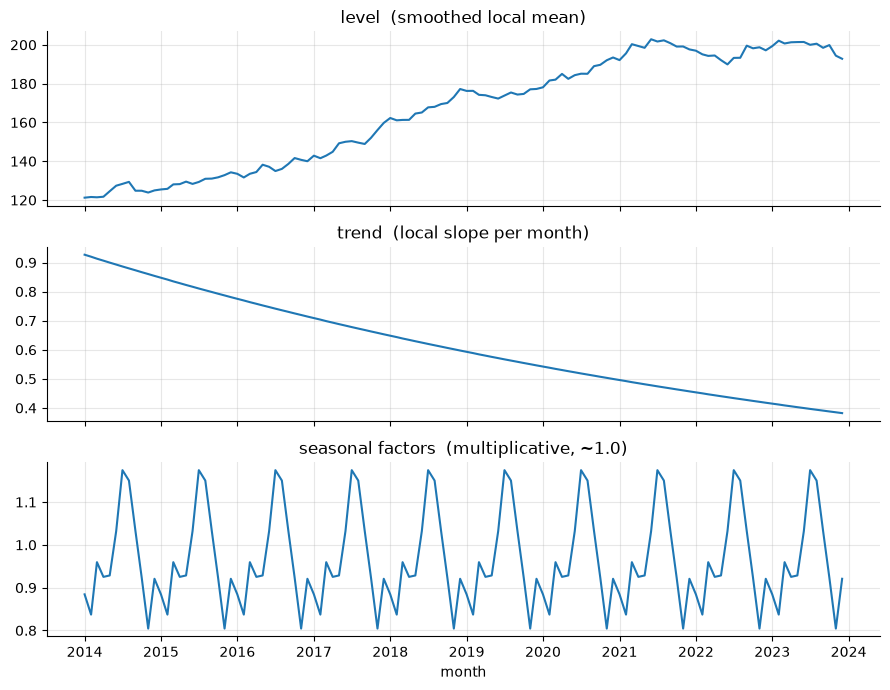

In [5]:
# Component interpretation: fit the multiplicative model with a damped trend.
hw_air = ExponentialSmoothing(air_train, trend="add", damped_trend=True, seasonal="mul",
                              seasonal_periods=12,
                              initialization_method="estimated").fit()
p = hw_air.params
print("Smoothing parameters (how fast each component reacts to new data):")
print(f"  alpha (level)     = {p['smoothing_level']:.3f}")
print(f"  beta  (trend)     = {p['smoothing_trend']:.3f}")
print(f"  gamma (seasonal)  = {p['smoothing_seasonal']:.3f}")
print(f"  phi   (damping)   = {p['damping_trend']:.3f}")

fig, axes = plt.subplots(3, 1, figsize=(9, 7), sharex=True)
axes[0].plot(hw_air.level);  axes[0].set_title("level  (smoothed local mean)")
axes[1].plot(hw_air.trend);  axes[1].set_title("trend  (local slope per month)")
axes[2].plot(hw_air.season); axes[2].set_title("seasonal factors  (multiplicative, ~1.0)")
axes[2].set_xlabel("month")
plt.show()

How to read this — the part interviewers probe:

- **alpha ≈ how much of the last observation flows into the level.** Small alpha
  (< ~0.2) = heavy smoothing, stable series; alpha near 1 = essentially a random walk
  (and ETS with alpha=1, no trend/seasonality *is* the naive forecast — simple
  exponential smoothing is ARIMA(0,1,1) in disguise).
- **gamma small** means seasonality is stable; the seasonal factors panel should look
  like a nearly-repeating pattern. If gamma is large the model thinks seasonality is
  drifting — often a sign of a misspecified seasonal type instead.
- **phi < 1** flattens long-horizon forecasts: the trend's total future contribution is
  $b_T(\phi + \phi^2 + \dots) \to b_T \phi/(1-\phi)$, a *finite* amount, instead of
  growing without bound.

The damping effect is easiest to see on the retail series, whose growth genuinely
flattens:

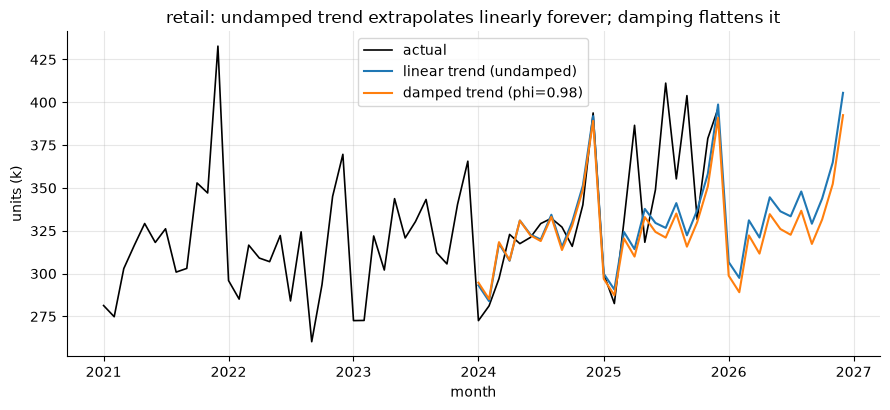

In [6]:
hw_ret_lin = ExponentialSmoothing(ret_train, trend="add", seasonal="add",
                                  seasonal_periods=12,
                                  initialization_method="estimated").fit()
hw_ret_damp = ExponentialSmoothing(ret_train, trend="add", damped_trend=True,
                                   seasonal="add", seasonal_periods=12,
                                   initialization_method="estimated").fit()

H_LONG = 36
future = pd.date_range(ret_train.index[-1] + pd.offsets.MonthBegin(),
                       periods=H_LONG, freq="MS")
fig, ax = plt.subplots()
ax.plot(retail.iloc[-60:], color="k", lw=1.2, label="actual")
ax.plot(future, hw_ret_lin.forecast(H_LONG), label="linear trend (undamped)")
ax.plot(future, hw_ret_damp.forecast(H_LONG),
        label=f"damped trend (phi={hw_ret_damp.params['damping_trend']:.2f})")
ax.set_title("retail: undamped trend extrapolates linearly forever; damping flattens it")
ax.set_xlabel("month"); ax.set_ylabel("units (k)")
ax.legend()
plt.show()

> Implementation note: `statsmodels` has two ETS implementations. `ExponentialSmoothing`
> (used here) is the classic Holt-Winters recursion — great for point forecasts and
> components, but it does not model the error term, so intervals come from simulation.
> `statsmodels.tsa.exponential_smoothing.ets.ETSModel` is the full state-space version
> with a proper likelihood and analytic intervals. For this notebook we use
> `ExponentialSmoothing` + `.simulate()`, which also generalizes to any model.

## 4. SARIMA: forecasting by correlation structure

ARIMA takes the opposite philosophical route from ETS: instead of naming components, it
models the **autocorrelation structure** of a (differenced) series directly.
$\text{SARIMA}(p,d,q)(P,D,Q)_m$ = AR and MA terms at regular lags, plus AR/MA terms at
seasonal lags, applied after $d$ regular and $D$ seasonal differences.

**Pragmatic order selection** — the workflow that survives contact with real data:

1. **Stabilize variance first.** Multiplicative series → log transform. (ETS handles
   multiplicativity natively; ARIMA is linear-Gaussian and needs the transform.)
2. **Choose $d$ and $D$ from stationarity logic**, not from the AIC grid: seasonal
   difference once if seasonality is strong, then difference once more if a trend
   remains. Verify with ADF/KPSS. Over-differencing shows up as a strong *negative*
   lag-1 ACF (≈ −0.5) — also worth checking.
3. **Read ACF/PACF of the differenced series** to get *candidate* (p,q)(P,Q) — this
   narrows the space and catches gross errors.
4. **Let a small AICc grid arbitrate** among the candidates. Eyeballing ACFs to pick
   the single final model is folklore; exhaustively searching huge grids overfits the
   criterion. Small grid + AICc (the small-sample-corrected AIC — with ~10 parameters
   on ~120 observations the correction matters) is the defensible middle.

One rule you must not break: **information criteria are only comparable between models
fit to the same transformed and differenced data.** AICc(log scale) vs AICc(raw scale),
or d=1 vs d=0, are different likelihoods — compare those by backtest (Section 8
demonstrates).

In [7]:
log_air_train = np.log(air_train)

def adf_kpss(s: pd.Series, label: str) -> None:
    adf_p = adfuller(s, autolag="AIC")[1]
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")           # KPSS p-value table truncation warning
        kpss_p = kpss(s, regression="c", nlags="auto")[1]
    verdict = "stationary-ish" if (adf_p < 0.05 and kpss_p > 0.05) else "not stationary"
    print(f"{label:32s} ADF p={adf_p:6.3f}   KPSS p={kpss_p:6.3f}   -> {verdict}")

adf_kpss(log_air_train, "log(air)")
adf_kpss(log_air_train.diff(12).dropna(), "log(air), D=1 (seasonal diff)")
d1D1 = log_air_train.diff(12).diff().dropna()
adf_kpss(d1D1, "log(air), D=1 then d=1")

log(air)                         ADF p= 0.373   KPSS p= 0.010   -> not stationary
log(air), D=1 (seasonal diff)    ADF p= 0.777   KPSS p= 0.024   -> not stationary
log(air), D=1 then d=1           ADF p= 0.001   KPSS p= 0.100   -> stationary-ish


ADF (H0: unit root) and KPSS (H0: stationary) test *opposite* nulls — using both guards
against low-power false comfort. Both agree the log series needs the seasonal and the
regular difference. Now read the correlograms of the differenced series:

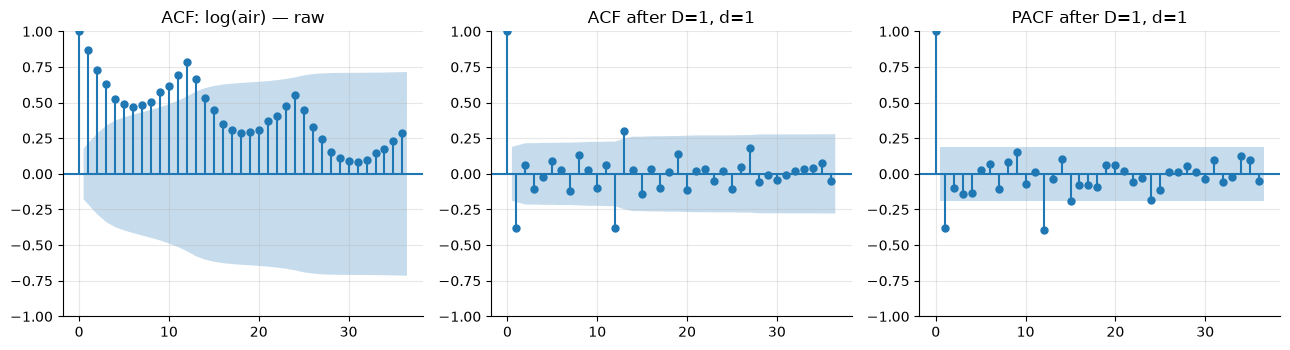

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
plot_acf(log_air_train, lags=36, ax=axes[0], title="ACF: log(air) — raw")
plot_acf(d1D1, lags=36, ax=axes[1], title="ACF after D=1, d=1")
plot_pacf(d1D1, lags=36, ax=axes[2], method="ywm", title="PACF after D=1, d=1")
plt.show()

Reading it like a practitioner:

- Raw log series: ACF decays slowly with a seasonal ripple — trend + seasonality,
  confirming the differencing choice.
- After differencing: a **negative spike at lag 1** (suggests non-seasonal MA(1)) and a
  **negative spike at lag 12** (suggests seasonal MA(1)), little else. The lag-1 ACF
  (≈ −0.38 here) stays meaningfully above −0.5, so there is no over-differencing red
  flag — Exercise 2 shows what that red flag looks like when you *do* over-difference.
- Candidates: $(0,1,1)(0,1,1)_{12}$ — the famous "airline model" — plus AR-flavored
  neighbors in case the MA reading is wrong.

The grid arbitrates. We keep it small and principled: $p,q \le 2$, $P,Q \le 1$
(differenced monthly business series essentially never need more), d=D=1 fixed by the
analysis above — 36 models, seconds to fit.

In [9]:
def aicc_grid(endog: pd.Series, d: int, D: int, m: int = 12,
              ps=(0, 1, 2), qs=(0, 1, 2), Ps=(0, 1), Qs=(0, 1)) -> pd.DataFrame:
    rows = []
    for p_, q_, P_, Q_ in itertools.product(ps, qs, Ps, Qs):
        try:
            r = SARIMAX(endog, order=(p_, d, q_),
                        seasonal_order=(P_, D, Q_, m)).fit(disp=False)
            rows.append({"order": f"({p_},{d},{q_})({P_},{D},{Q_})[{m}]",
                         "p": p_, "q": q_, "P": P_, "Q": Q_,
                         "n_params": p_ + q_ + P_ + Q_ + 1,
                         "AICc": r.aicc,
                         "converged": bool(r.mle_retvals.get("converged", True))})
        except (np.linalg.LinAlgError, ValueError):
            continue
    return (pd.DataFrame(rows)
            .sort_values("AICc", ignore_index=True))

grid_air = aicc_grid(log_air_train, d=1, D=1)
print("Top of the AICc grid, log(air):")
print(grid_air.head(6).to_string(index=False))

best_air = grid_air.iloc[0]
ORDER_AIR = (int(best_air.p), 1, int(best_air.q))
SORDER_AIR = (int(best_air.P), 1, int(best_air.Q), 12)
print(f"\nselected: SARIMA{ORDER_AIR}x{SORDER_AIR} on log scale")

Top of the AICc grid, log(air):
             order  p  q  P  Q  n_params      AICc  converged
(0,1,1)(0,1,1)[12]  0  1  0  1         3 -460.7554       True
(0,1,1)(1,1,1)[12]  0  1  1  1         4 -458.9864       True
(1,1,1)(0,1,1)[12]  1  1  0  1         4 -458.9283       True
(0,1,2)(0,1,1)[12]  0  2  0  1         4 -458.8143       True
(1,1,0)(0,1,1)[12]  1  0  0  1         3 -458.4341       True
(2,1,1)(0,1,1)[12]  2  1  0  1         5 -457.1113      False

selected: SARIMA(0, 1, 1)x(0, 1, 1, 12) on log scale


Note how flat the top of the table is — several models within ~2 AICc of each other.
That is typical, and it is *model-selection uncertainty*: remember it when we find
intervals too narrow later. Next, the diagnostics that decide whether the winner is
actually adequate:

- **Ljung-Box** tests whether the first $K$ residual autocorrelations are jointly zero
  (pass `model_df = p+q+P+Q` so the degrees of freedom are right — a detail many
  candidates miss). A *low* p-value means structure is left over: the model failed to
  capture the dynamics, and its intervals will be too narrow.
- The **residual ACF / correlogram** shows *where* the leftover structure lives (e.g. a
  spike at lag 12 means seasonal dynamics remain → increase Q or check D).
- Passing diagnostics means "not obviously inadequate" — it does not certify forecasts.

Ljung-Box on residuals (model_df=2):
    lb_stat  lb_pvalue
12  12.2997     0.2655
24  28.7571     0.1519


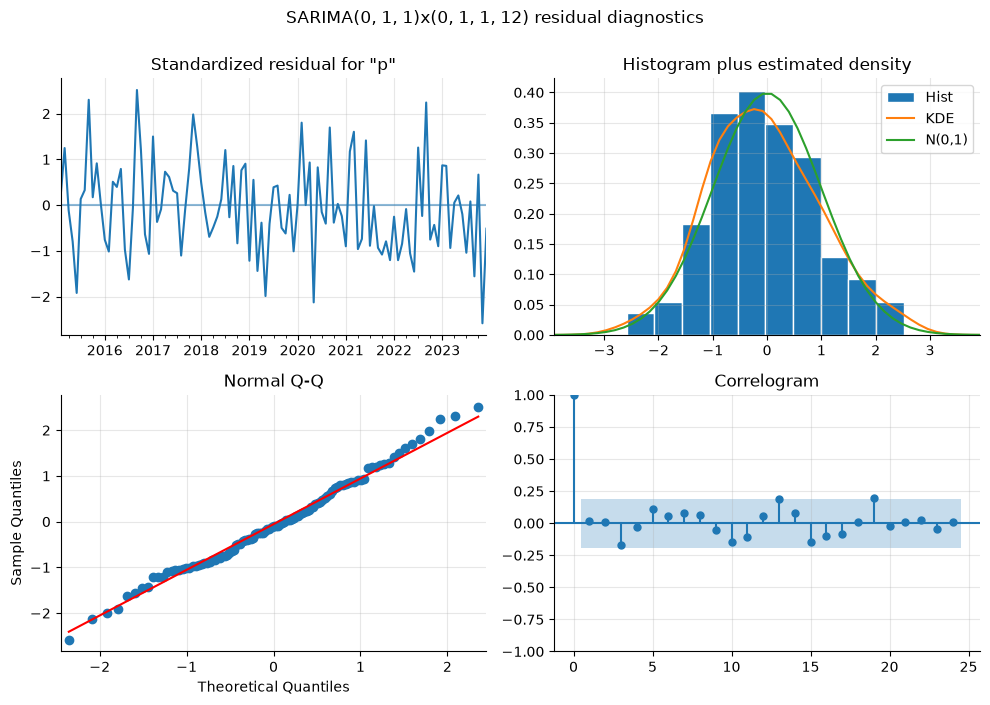

In [10]:
sar_air = SARIMAX(log_air_train, order=ORDER_AIR, seasonal_order=SORDER_AIR).fit(disp=False)
model_df = sum(ORDER_AIR[::2]) + sum(SORDER_AIR[:3:2])       # p+q+P+Q
resid = sar_air.resid[13:]                                   # drop differencing burn-in
lb = acorr_ljungbox(resid, lags=[12, 24], model_df=model_df, return_df=True)
print(f"Ljung-Box on residuals (model_df={model_df}):")
print(lb)

fig = sar_air.plot_diagnostics(figsize=(10, 7), lags=24)
fig.suptitle(f"SARIMA{ORDER_AIR}x{SORDER_AIR} residual diagnostics", y=1.0)
plt.show()

In [11]:
# Same pragmatic pipeline for retail (additive structure -> raw scale; strong seasonality
# and trend -> d=1, D=1). We reuse the grid and just report the winner.
grid_ret = aicc_grid(ret_train, d=1, D=1)
best_ret = grid_ret.iloc[0]
ORDER_RET = (int(best_ret.p), 1, int(best_ret.q))
SORDER_RET = (int(best_ret.P), 1, int(best_ret.Q), 12)
print(grid_ret.head(4).to_string(index=False))
print(f"\nselected for retail: SARIMA{ORDER_RET}x{SORDER_RET} on raw scale")

sar_ret = SARIMAX(ret_train, order=ORDER_RET, seasonal_order=SORDER_RET).fit(disp=False)
lb_ret = acorr_ljungbox(sar_ret.resid[13:], lags=[12, 24],
                        model_df=sum(ORDER_RET[::2]) + sum(SORDER_RET[:3:2]),
                        return_df=True)
print("\nLjung-Box, retail residuals:")
print(lb_ret)

             order  p  q  P  Q  n_params      AICc  converged
(0,1,1)(0,1,1)[12]  0  1  0  1         3 1007.4809       True
(0,1,1)(1,1,1)[12]  0  1  1  1         4 1008.6389       True
(0,1,2)(0,1,1)[12]  0  2  0  1         4 1009.6130       True
(1,1,1)(0,1,1)[12]  1  1  0  1         4 1009.6165       True

selected for retail: SARIMA(0, 1, 1)x(0, 1, 1, 12) on raw scale

Ljung-Box, retail residuals:
    lb_stat  lb_pvalue
12   6.4433     0.7767
24  21.0525     0.5175


## 5. Prediction intervals: fan charts, and whether they can be trusted

A point forecast without an interval is a liability: inventory, staffing, and finance
decisions all consume the *distribution*. For ARIMA the h-step variance accumulates the
innovation variance through the MA(∞) weights, so intervals **widen with horizon**; with
d ≥ 1 they widen without bound. ETS intervals we get by simulating future paths.

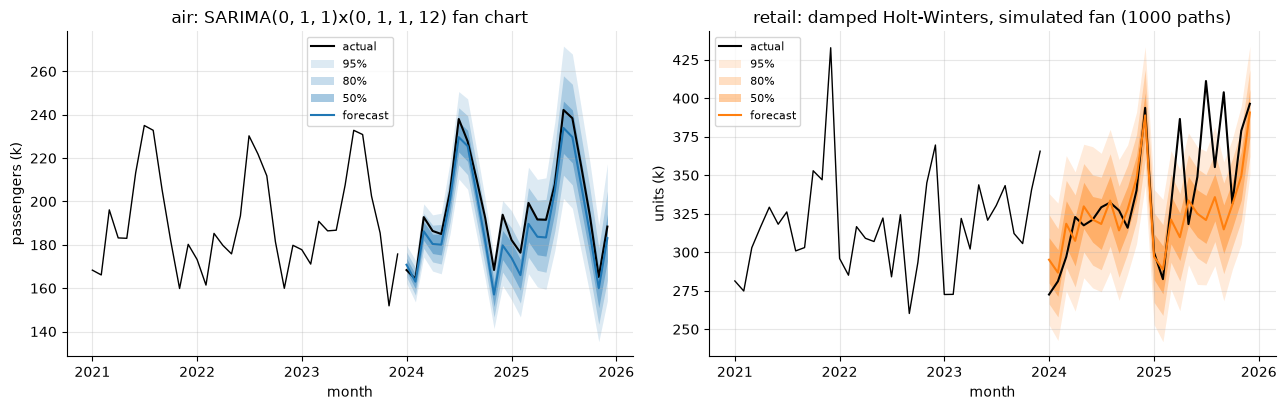

air 95% interval width: h=1: 17.6   h=12: 39.2   h=24: 63.2   (x3.6 from h=1 to h=24)


In [12]:
H_FAN = 24
fc = sar_air.get_forecast(H_FAN)
fan_index = air_test.index
sims = hw_ret_damp.simulate(H_FAN, anchor="end", repetitions=1000, error="add",
                            random_state=42)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))

ax = axes[0]
ax.plot(air.iloc[-60:-24], color="k", lw=1)
ax.plot(air_test, color="k", lw=1.5, label="actual")
for alpha, shade in [(0.05, 0.15), (0.20, 0.25), (0.50, 0.40)]:
    ci = np.exp(fc.conf_int(alpha=alpha))
    ax.fill_between(fan_index, ci.iloc[:, 0], ci.iloc[:, 1],
                    color="tab:blue", alpha=shade, lw=0,
                    label=f"{100 * (1 - alpha):.0f}%")
ax.plot(fan_index, np.exp(fc.predicted_mean), color="tab:blue", lw=1.5, label="forecast")
ax.set_title(f"air: SARIMA{ORDER_AIR}x{SORDER_AIR} fan chart")
ax.set_xlabel("month"); ax.set_ylabel("passengers (k)"); ax.legend(fontsize=8)

ax = axes[1]
ax.plot(retail.iloc[-60:-24], color="k", lw=1)
ax.plot(ret_test, color="k", lw=1.5, label="actual")
for lo, hi, shade in [(0.025, 0.975, 0.15), (0.10, 0.90, 0.25), (0.25, 0.75, 0.40)]:
    ax.fill_between(sims.index, sims.quantile(lo, axis=1), sims.quantile(hi, axis=1),
                    color="tab:orange", alpha=shade, lw=0,
                    label=f"{100 * (hi - lo):.0f}%")
ax.plot(sims.index, sims.mean(axis=1), color="tab:orange", lw=1.5, label="forecast")
ax.set_title("retail: damped Holt-Winters, simulated fan (1000 paths)")
ax.set_xlabel("month"); ax.set_ylabel("units (k)"); ax.legend(fontsize=8)
plt.show()

ci95 = np.exp(fc.conf_int(alpha=0.05))
w = (ci95.iloc[:, 1] - ci95.iloc[:, 0]).to_numpy()
print(f"air 95% interval width: h=1: {w[0]:.1f}   h=12: {w[11]:.1f}   "
      f"h=24: {w[23]:.1f}   (x{w[23] / w[0]:.1f} from h=1 to h=24)")

### The empirical coverage check

These fans are *model-based*: they are correct **if the model is correct** — Gaussian
innovations, parameters known exactly, no structural change. None of that is true in
production, and every violation points the same direction: **intervals too narrow**.

The only honest check is empirical: backtest with rolling origins, collect the 95%
intervals at each horizon, and count how often the realized value landed inside. We run
one rolling-origin backtest here and reuse its output for the accuracy comparison in
Section 6:

- Origins $T = 120, \dots, 132$ (13 origins across the final two years), expanding
  training window, horizon $H = 12$, **models fully refit at every origin** — orders
  were selected on data before the first origin, so there is no selection leakage.
- For each (origin, model, horizon): point forecast, 95% interval (ETS via 500
  simulated paths, SARIMA analytic), the realized actual, and the MASE scaling factor
  computed from that origin's training window only.

In [13]:
H = 12
ETS_CFG = {
    "air": (dict(trend="add", damped_trend=True, seasonal="mul", seasonal_periods=12),
            "mul"),
    "retail": (dict(trend="add", damped_trend=True, seasonal="add", seasonal_periods=12),
               "add"),
}
SAR_CFG = {"air": (ORDER_AIR, SORDER_AIR, True),      # (order, seasonal_order, use_log)
           "retail": (ORDER_RET, SORDER_RET, False)}

def run_backtest(y: pd.Series, series: str, origins) -> pd.DataFrame:
    yv = y.to_numpy()
    ets_kwargs, ets_err = ETS_CFG[series]
    order, sorder, use_log = SAR_CFG[series]
    rows = []
    for T in origins:
        train = y.iloc[:T]
        actual = yv[T:T + H]
        scale = np.mean(np.abs(yv[12:T] - yv[:T - 12]))    # in-sample snaive MAE
        fcs = {b: (fn(train.to_numpy(), H), None, None) for b, fn in BASELINES.items()}

        ets = ExponentialSmoothing(train, initialization_method="estimated",
                                   **ets_kwargs).fit()
        sims = ets.simulate(H, anchor="end", repetitions=500, error=ets_err,
                            random_state=T)
        fcs["ETS"] = (ets.forecast(H).to_numpy(),
                      sims.quantile(0.025, axis=1).to_numpy(),
                      sims.quantile(0.975, axis=1).to_numpy())

        endog = np.log(train) if use_log else train
        sres = SARIMAX(endog, order=order, seasonal_order=sorder).fit(disp=False)
        fo = sres.get_forecast(H)
        mean, ci = fo.predicted_mean.to_numpy(), fo.conf_int(alpha=0.05).to_numpy()
        if use_log:
            mean, ci = np.exp(mean), np.exp(ci)
        fcs["SARIMA"] = (mean, ci[:, 0], ci[:, 1])

        for model, (f, lo, hi) in fcs.items():
            for h in range(H):
                rows.append({"series": series, "model": model, "origin": T, "h": h + 1,
                             "forecast": f[h],
                             "lo": np.nan if lo is None else lo[h],
                             "hi": np.nan if hi is None else hi[h],
                             "actual": actual[h], "scale": scale})
    return pd.DataFrame(rows)

origins = range(120, 133)                     # 13 origins; T + 12 <= 144
bt = pd.concat([run_backtest(air, "air", origins),
                run_backtest(retail, "retail", origins)], ignore_index=True)
print(f"backtest table: {len(bt)} rows "
      f"({bt.origin.nunique()} origins x {bt.model.nunique()} models x {H} horizons x 2 series)")

backtest table: 1560 rows (13 origins x 5 models x 12 horizons x 2 series)


Empirical coverage of NOMINAL 95% intervals (rolling-origin backtest):
bucket         h=1-4  h=5-8  h=9-12  all h
series model                              
air    ETS     100.0  100.0   100.0  100.0
       SARIMA  100.0  100.0   100.0  100.0
retail ETS      98.1   88.5    76.9   87.8
       SARIMA   98.1   88.5    76.9   87.8


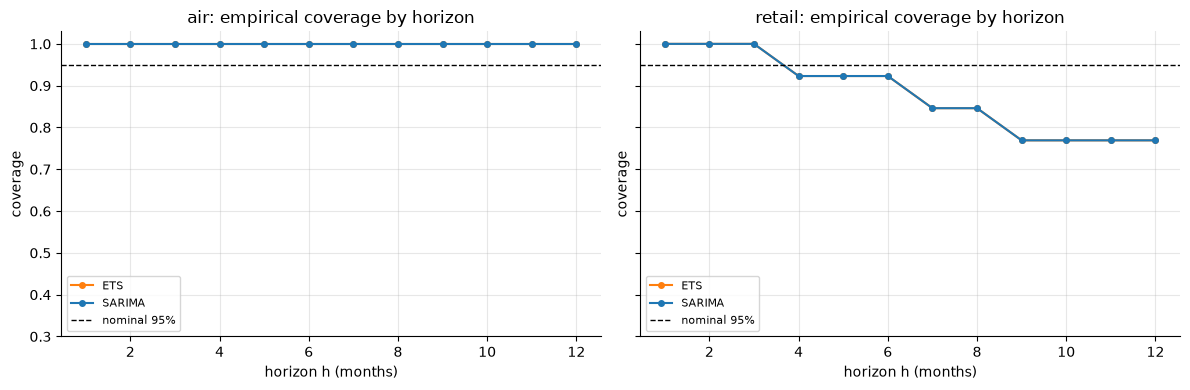

In [14]:
iv = bt[bt.model.isin(["ETS", "SARIMA"])].copy()
iv["hit"] = (iv.actual >= iv.lo) & (iv.actual <= iv.hi)
iv["bucket"] = pd.cut(iv.h, bins=[0, 4, 8, 12], labels=["h=1-4", "h=5-8", "h=9-12"])

cov = (iv.groupby(["series", "model", "bucket"], observed=True)["hit"].mean()
         .unstack("bucket"))
cov["all h"] = iv.groupby(["series", "model"])["hit"].mean()
print("Empirical coverage of NOMINAL 95% intervals (rolling-origin backtest):")
print((cov * 100).round(1))

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, s in zip(axes, ["air", "retail"]):
    for model, color in [("ETS", "tab:orange"), ("SARIMA", "tab:blue")]:
        sub = (iv[(iv.series == s) & (iv.model == model)]
               .groupby("h")["hit"].mean())
        ax.plot(sub.index, sub.to_numpy(), marker="o", ms=4, color=color, label=model)
    ax.axhline(0.95, color="k", ls="--", lw=1, label="nominal 95%")
    ax.set_ylim(0.3, 1.03)
    ax.set_title(f"{s}: empirical coverage by horizon")
    ax.set_xlabel("horizon h (months)"); ax.set_ylabel("coverage")
    ax.legend(fontsize=8)
plt.show()

The pattern this experiment is designed to show (read your run's numbers off the table):

- On **`air`** — where the fitted model class essentially *contains* the true generating
  process — coverage sits at (here even slightly above) nominal. Model-based intervals
  are honest, if mildly conservative, when the model is right.
- On **`retail`** — promo spikes the Gaussian likelihood can't see, plus a trend break
  inside the backtest window — coverage falls **materially below 95%**, and degrades
  steadily with horizon as forecasts extrapolate a stale trend further and further.
  This is the production-typical case: *your data is retail, not air.*

Why nominal intervals under-cover, in decreasing order of typical importance:

1. **Structural change** — the future is not drawn from the fitted process at all.
2. **Model misspecification** — heavy-tailed/asymmetric errors (promos!), unmodeled
   heteroskedasticity, leftover autocorrelation (this is what Ljung-Box guards).
3. **Parameter uncertainty ignored** — intervals treat estimated $\theta$ as known.
4. **Selection uncertainty ignored** — we searched a grid, then pretended the winner
   was prespecified. The flat AICc table earlier says otherwise.

The pragmatic fix is empirical calibration: use backtest residual quantiles per horizon
to widen (or replace) the model intervals — a conformal-flavored recipe you implement in
Exercise 3.

## 6. Rolling-origin evaluation and the metric zoo

The backtest above is the correct general design; make sure you can defend each choice:

- **Rolling (expanding) origin**: train on data through $T$, forecast $T+1..T+H$,
  advance $T$, refit. Mirrors production. A single train/test split is one sample of
  forecast difficulty (Section 8 shows rankings flip across origins); random K-fold on
  time-ordered data is leakage, full stop.
- **Refit cadence and window** should mirror what production will do (we refit every
  origin with an expanding window; a sliding window adapts faster after breaks).
- **Report by horizon**, not just pooled — models that win at h=1 often lose at h=12.
- **Any tuning/order selection must use data before the backtest origins** — otherwise
  the backtest flatters the tuned model.

In [15]:
def metric_table(bt_frame: pd.DataFrame) -> pd.DataFrame:
    def _metrics(g: pd.DataFrame) -> pd.Series:
        e = g.forecast - g.actual
        return pd.Series({
            "MAE": np.mean(np.abs(e)),
            "RMSE": np.sqrt(np.mean(e ** 2)),
            "MAPE%": 100 * np.mean(np.abs(e) / np.abs(g.actual)),
            "sMAPE%": 100 * np.mean(2 * np.abs(e) / (np.abs(g.actual) + np.abs(g.forecast))),
            "MASE": np.mean(np.abs(e) / g.scale),
        })
    out = (bt_frame.groupby(["series", "model"])[["forecast", "actual", "scale"]]
           .apply(_metrics))
    return out.reindex(["naive", "snaive", "drift", "ETS", "SARIMA"], level="model")

summary = metric_table(bt)
print("Rolling-origin backtest, all horizons pooled (13 origins x h=1..12):")
print(summary.round(3))

Rolling-origin backtest, all horizons pooled (13 origins x h=1..12):
                  MAE    RMSE   MAPE%  sMAPE%   MASE
series model                                        
air    naive   23.782  29.899  11.785  11.978  2.528
       snaive   8.075   9.611   4.235   4.366  0.859
       drift   23.986  30.148  12.007  11.947  2.552
       ETS      4.718   5.563   2.434   2.463  0.499
       SARIMA   5.210   6.221   2.688   2.717  0.552
retail naive   35.512  44.859  10.388  10.628  1.427
       snaive  22.282  31.330   6.242   6.579  0.901
       drift   34.598  43.659  10.222  10.284  1.390
       ETS     19.083  31.348   5.254   5.574  0.773
       SARIMA  18.359  29.911   5.073   5.359  0.743


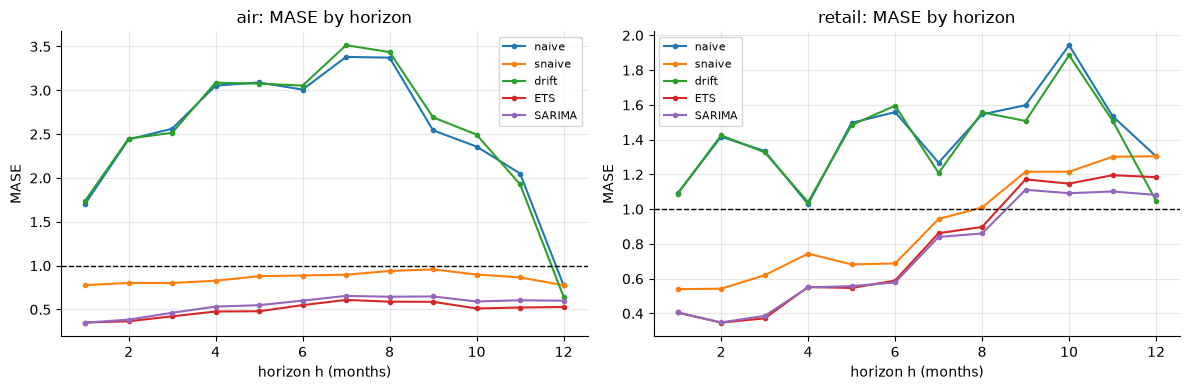

In [16]:
mase_h = (bt.assign(q=lambda d: np.abs(d.forecast - d.actual) / d.scale)
            .groupby(["series", "model", "h"])["q"].mean().reset_index())
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=False)
for ax, s in zip(axes, ["air", "retail"]):
    for model in ["naive", "snaive", "drift", "ETS", "SARIMA"]:
        sub = mase_h[(mase_h.series == s) & (mase_h.model == model)]
        ax.plot(sub.h, sub.q, marker="o", ms=3, label=model)
    ax.axhline(1.0, color="k", ls="--", lw=1)
    ax.set_title(f"{s}: MASE by horizon")
    ax.set_xlabel("horizon h (months)"); ax.set_ylabel("MASE")
    ax.legend(fontsize=8)
plt.show()

How to read the table and plot:

- On **`air`**, ETS and SARIMA beat every baseline decisively — clean multiplicative
  structure is exactly what they are built for. Naive and drift are not in the race on
  seasonal data.
- On **`retail`**, the margin over seasonal naive shrinks a lot: noise, promos, and the
  trend break eat the structural advantage. This is the honest, typical outcome on
  business data — and why the baseline row belongs in every model-comparison table you
  ever present.
- **MASE < 1** means "smaller absolute error than a one-step in-sample seasonal-naive
  forecast" — note the benchmark is the *in-sample one-step* snaive, so the out-of-sample
  multi-step `snaive` row itself typically sits *above* 1. MASE compares models on a
  common, scale-free yardstick; it does not literally read as "beats the snaive row".

### Metric pathologies — why MASE is the default

MAPE is the most-used and most-broken forecast metric. Two failure modes, demonstrated:

In [17]:
# Pathology 1: MAPE explodes near zero (and is undefined at zero).
net = pd.Series(rng.normal(3.0, 4.0, 48))          # e.g. monthly net demand, crosses zero
f_const = np.full(48, net.mean())
ape = np.abs(f_const - net) / np.abs(net)
print(f"near-zero series:  MAE = {np.mean(np.abs(f_const - net)):.2f}   "
      f"MAPE = {100 * ape.mean():,.0f}%   max single APE = {100 * ape.max():,.0f}%")
worst = ape.nlargest(3)
print("worst rows (tiny |actual| -> APE blows up):")
print(pd.DataFrame({"actual": net[worst.index], "APE%": 100 * worst}).round(1))

# Pathology 2: MAPE is asymmetric -- same absolute miss, different penalty.
print(f"\nover-forecast  (actual=100, forecast=150): APE = {100 * 50 / 100:.0f}%")
print(f"under-forecast (actual=150, forecast=100): APE = {100 * 50 / 150:.0f}%")

# Consequence: the MAPE-optimal forecast is biased LOW. Find the constant forecast that
# minimizes each metric for a right-skewed demand distribution:
demand = rng.gamma(2.0, 50.0, 20000)               # mean 100, median ~84
cands = np.linspace(20, 200, 1000)
mape_c = [np.mean(np.abs(c - demand) / demand) for c in cands]
print(f"\nright-skewed demand: mean = {demand.mean():.1f}, "
      f"median = {np.median(demand):.1f}")
print(f"MAPE-optimal constant forecast = {cands[np.argmin(mape_c)]:.1f}  "
      "<- below the median: optimizing MAPE rewards under-forecasting")

# sMAPE is bounded but has its own asymmetry (penalizes under-forecasting) and is
# degenerate at zero:
def smape1(y, f):
    return 200 * abs(f - y) / (abs(y) + abs(f))
print(f"\nsMAPE(actual=100, forecast=110) = {smape1(100, 110):.2f}%")
print(f"sMAPE(actual=100, forecast= 90) = {smape1(100, 90):.2f}%   <- same miss, bigger penalty")
print(f"sMAPE(actual=0,   forecast=  5) = {smape1(0, 5):.0f}%   <- pinned to the max")

near-zero series:  MAE = 2.65   MAPE = 169%   max single APE = 3,948%
worst rows (tiny |actual| -> APE blows up):
    actual    APE%
12     0.1  3948.5
26    -1.1   409.4
25    -1.2   384.2

over-forecast  (actual=100, forecast=150): APE = 50%
under-forecast (actual=150, forecast=100): APE = 33%

right-skewed demand: mean = 100.6, median = 84.2
MAPE-optimal constant forecast = 33.2  <- below the median: optimizing MAPE rewards under-forecasting

sMAPE(actual=100, forecast=110) = 9.52%
sMAPE(actual=100, forecast= 90) = 10.53%   <- same miss, bigger penalty
sMAPE(actual=0,   forecast=  5) = 200%   <- pinned to the max


Scorecard for the zoo:

| Metric | Scale-free? | Defined at y=0? | Optimized by | Gotcha |
|---|---|---|---|---|
| MAE | no | yes | median | can't compare across series |
| RMSE | no | yes | mean | outlier-dominated (promos!) |
| MAPE | yes | **no** | ~biased-low quantile | explodes near zero; rewards under-forecasting |
| sMAPE | yes | degenerate | (messy) | bounded at 200%; penalizes under-forecasting |
| **MASE** | **yes** | **yes** | median | needs a training window for the scale |

**MASE** — mean of $|e|$ divided by the in-sample one-step seasonal-naive MAE — is the
sane default: scale-free (aggregate it across 10,000 SKUs), defined for intermittent /
zero-crossing series, benchmark-anchored, no perverse bias incentive. Use RMSE alongside
it when large errors are disproportionately costly, and report intervals coverage — a
point metric alone never tells you the intervals are lying.

## 7. Where Prophet-style decomposable models fit (concept only)

Prophet (and its descendants) fits a **curve-fitting regression**, not a stochastic
process: $y(t) = g(t) + s(t) + h(t) + \varepsilon_t$ with a piecewise-linear or logistic
trend $g$ (automatic changepoints), Fourier-series seasonalities $s$, holiday dummies
$h$, and — crucially — **no dependence on lagged $y$**.

What that buys you:
- Multiple seasonalities (weekly + yearly on daily data) and irregular holiday effects,
  which are awkward in SARIMA (one seasonal period) and ETS.
- Robustness to missing timestamps and outliers; no differencing/stationarity decisions;
  interpretable components; fast analyst-in-the-loop tuning ("add a changepoint here").

What it costs you:
- Errors are treated as independent, but ignoring lagged $y$ leaves them autocorrelated
  → **intervals are unreliable** and one-step accuracy lags autoregressive models.
- On plain monthly business series (like this notebook's), well-configured ETS/SARIMA
  typically beat it — that is the recurring M-competition-style finding.

Positioning rule of thumb: **ETS/SARIMA for a handful of important series** at monthly /
weekly granularity; **Prophet-style when you need holiday/multi-seasonal structure on
daily data with analyst tuning at moderate scale**; **global ML models (see the ML
forecasting notebook in this folder) when you have thousands of related series** and can
learn across them. In every case, baselines and rolling-origin evaluation stay the same.

## 8. Pitfalls

### Pitfall 1: comparing information criteria across transforms

AIC/AICc/BIC are functions of the likelihood *of the data as modeled*. Fit one model to
$y$ and another to $\log y$ and the two likelihoods live on different scales — the
comparison is meaningless without the Jacobian correction.

In [18]:
sar_raw = SARIMAX(air_train, order=ORDER_AIR, seasonal_order=SORDER_AIR).fit(disp=False)
print(f"AICc, SARIMA on raw air : {sar_raw.aicc:10.1f}")
print(f"AICc, SARIMA on log air : {sar_air.aicc:10.1f}   <- NOT comparable to the raw one")

# In principle the Jacobian of y -> log y fixes this: loglik on the raw-y scale
# = loglik on the log scale - sum(log y). But WHICH observations' log y? The d=1, D=1
# differencing consumes 13 observations whose contribution to the state-space likelihood
# is (approximately) diffuse -- and the verdict flips depending on how you count them:
log_y = np.log(air_train)
for label, jac in [("all 120 obs", log_y.sum()),
                   ("107 post-burn-in obs", log_y[13:].sum())]:
    mapped = sar_air.aicc + 2 * jac
    verdict = "raw model 'wins'" if mapped > sar_raw.aicc else "log model 'wins'"
    print(f"log-AICc mapped to raw scale, Jacobian over {label:22s}: "
          f"{mapped:8.1f}  -> {verdict}")

AICc, SARIMA on raw air :      650.6
AICc, SARIMA on log air :     -460.8   <- NOT comparable to the raw one
log-AICc mapped to raw scale, Jacobian over all 120 obs           :    752.5  -> raw model 'wins'
log-AICc mapped to raw scale, Jacobian over 107 post-burn-in obs  :    628.4  -> log model 'wins'


The correction itself is fragile once differencing and diffuse initialization are
involved — the comparison flips with the bookkeeping. Treat cross-transform IC
comparisons as undefined in practice. The robust arbiters for "raw or log?" are the
residual-vs-fitted plot (Section 3) and a backtest scored on the *original* scale.

### Pitfall 2: naive back-transform of log forecasts

If the forecast on the log scale is $N(\mu_h, \sigma_h^2)$, then $e^{\mu_h}$ is the
**median**, not the mean, of the original-scale distribution; the mean is
$e^{\mu_h + \sigma_h^2 / 2}$. Quantiles (and therefore intervals) transform exactly
through monotone maps — point *means* do not.

In [19]:
mu, sigma = np.log(100.0), 0.5        # a noisy weekly-SKU-like forecast distribution
draws = np.exp(rng.normal(mu, sigma, 200_000))
print(f"exp(mu) (naive back-transform)      : {np.exp(mu):7.1f}   = median "
      f"(simulated median {np.median(draws):.1f})")
print(f"exp(mu + sigma^2/2) (bias-corrected): {np.exp(mu + sigma ** 2 / 2):7.1f}   "
      f"= mean   (simulated mean {draws.mean():.1f})")

# On this notebook's airline series sigma_h is tiny, so the correction is negligible:
s2 = (((np.log(ci95.iloc[:, 1]) - np.log(ci95.iloc[:, 0])) / (2 * 1.96)) ** 2).to_numpy()
print(f"\nair SARIMA: correction factor exp(s2/2) at h=24 = {np.exp(s2[-1] / 2):.4f}")
print("-> negligible here, but at SKU level (sigma ~ 0.5) the naive back-transform\n"
      "   under-forecasts the mean by ~13% PER SERIES; summed into a network-level plan,\n"
      "   the medians do not add up to the median of the total, and the plan runs short.")

exp(mu) (naive back-transform)      :   100.0   = median (simulated median 99.9)
exp(mu + sigma^2/2) (bias-corrected):   113.3   = mean   (simulated mean 113.3)

air SARIMA: correction factor exp(s2/2) at h=24 = 1.0038
-> negligible here, but at SKU level (sigma ~ 0.5) the naive back-transform
   under-forecasts the mean by ~13% PER SERIES; summed into a network-level plan,
   the medians do not add up to the median of the total, and the plan runs short.


### Pitfall 3: crowning a winner from a single split

One holdout window is a single draw of forecast difficulty. Rankings are unstable across
origins — the same backtest table we already computed shows it:

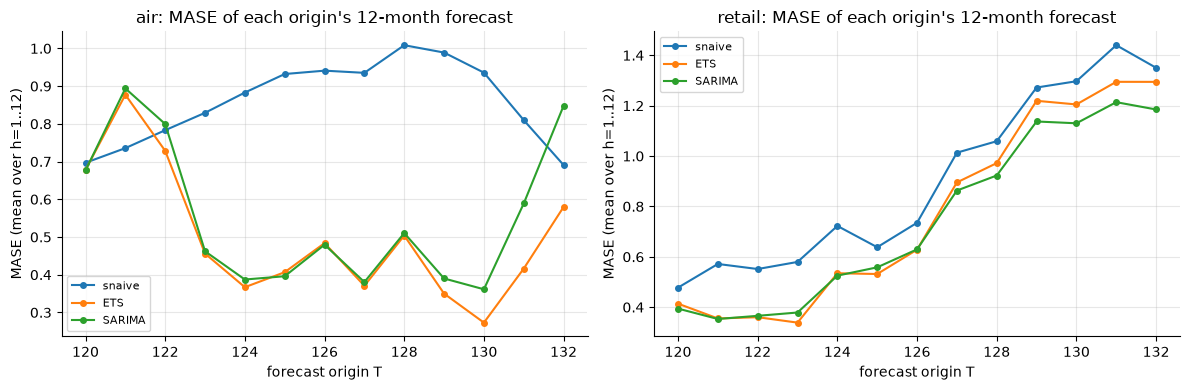

air     — origin-by-origin winner counts: {'ETS': 9, 'SARIMA': 3, 'snaive': 1}
retail  — origin-by-origin winner counts: {'SARIMA': 9, 'ETS': 4}


In [20]:
per_origin = (bt.assign(q=lambda d: np.abs(d.forecast - d.actual) / d.scale)
                .groupby(["series", "origin", "model"])["q"].mean()
                .unstack("model")[["snaive", "ETS", "SARIMA"]])

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=False)
for ax, s in zip(axes, ["air", "retail"]):
    per_origin.loc[s].plot(ax=ax, marker="o", ms=4)
    ax.set_title(f"{s}: MASE of each origin's 12-month forecast")
    ax.set_xlabel("forecast origin T"); ax.set_ylabel("MASE (mean over h=1..12)")
    ax.legend(fontsize=8)
plt.show()

winners = per_origin.idxmin(axis=1)
for s in ["air", "retail"]:
    counts = winners.loc[s].value_counts().to_dict()
    print(f"{s:7s} — origin-by-origin winner counts: {counts}")

Had you evaluated on exactly one of those origins, you could have crowned any of several
"best" models — in this run even seasonal naive takes an origin outright on `air`.
Aggregate over origins, check the ranking is stable, and demand a margin large enough to
pay for the extra complexity (for a formal pairwise test of equal forecast accuracy,
look up Diebold-Mariano).

## 9. Interview corner

**Q1. "How do you evaluate a forecasting model?"**
Strong answer: rolling-origin backtest that mirrors production (same refit cadence,
same horizon, tuning done strictly before the evaluation origins); always against naive
/ seasonal-naive baselines; metrics stratified by horizon; MASE (or RMSE if big errors
are the cost driver) rather than MAPE; *and* empirical coverage of the prediction
intervals, not just point accuracy; check ranking stability across origins. Bonus
points: mention that a single train/test split is one draw of difficulty, and
Diebold-Mariano for formal comparison.

**Q2. "Why MASE over MAPE?"**
MAPE is undefined at zero, explodes near zero, and is asymmetric — the same absolute
miss costs more when the actual is small, so optimizing MAPE systematically rewards
under-forecasting (we showed the MAPE-optimal forecast sits below the median). sMAPE
fixes boundedness but keeps asymmetry and a degenerate zero case. MASE divides by the
in-sample seasonal-naive MAE: scale-free (aggregates across series), defined with
zeros, and benchmark-anchored — values near/above 1 immediately flag "not beating a
trivial model".

**Q3. "ETS vs ARIMA — when would you use each?"**
Different philosophies: ETS models explicit level/trend/seasonal components; ARIMA
models autocorrelation of a differenced series. ETS handles multiplicative seasonality
natively and is a robust automatic default for short seasonal business series; damped
ETS is a famously strong M-competition performer. ARIMA wins when dynamics matter —
stationary mean-reverting series, effects propagating through lags — and SARIMAX gives
you exogenous regressors (promos, price, holidays) cleanly. The families overlap
(SES ≡ ARIMA(0,1,1); Holt ≡ ARIMA(0,2,2); additive HW ≈ airline-like SARIMA) but
neither contains the other: multiplicative ETS has no ARIMA equivalent; stationary
ARMA has no ETS equivalent. Senior answer ends with: "in practice I backtest both —
and their average often beats either."

**Q4. "Your 95% intervals only cover 80% in production. Why? What do you do?"**
Causes in likely order: structural change (the future isn't the fitted process);
misspecification — heavy-tailed/asymmetric errors, heteroskedasticity (wrong
additive/multiplicative choice), leftover autocorrelation (check Ljung-Box); parameter
uncertainty ignored by plug-in intervals; selection uncertainty (grid-searched, then
treated the winner as prespecified). Fixes: empirically calibrate interval widths from
backtest residual quantiles per horizon (conformal-style); simulate with parameter
draws or bootstrap residuals; re-examine the variance model. And keep monitoring
coverage as a production metric, like you monitor accuracy.

**Q5. "We have 10,000 SKUs to forecast weekly. Still SARIMA?"**
Per-series classical models are the *baseline tier*: cheap, parallelizable,
surprisingly hard to beat for stable sellers — but they can't share strength across
series or use rich covariates. At that scale move to global models (one gradient
boosting / deep model over all series with series-level features), keep
seasonal-naive + ETS as the benchmark every SKU must beat, aggregate MASE for
comparability, and handle hierarchy (SKU→category→total) with reconciliation. Cold
starts and intermittent demand (Croston-style or count models) need special handling.

**Q6. "When is the naive forecast the right production model?"**
When the series is close to a random walk (many financial and some operational
series), when history is too short to estimate seasonality, or when the accuracy gain
of a complex model doesn't cover its maintenance/latency/explanation costs. The
baseline *is* the model until something beats it out of sample by a margin that pays
rent — saying this plainly is a senior signal, not a cop-out.

**Q7. "Why did you difference the series for ARIMA instead of letting the grid pick d?"**
Because information criteria are not comparable across different d/D (the likelihood
is computed on different data), so d and D must come from stationarity reasoning —
unit-root tests with opposite nulls (ADF + KPSS), seasonal strength, and checking for
over-differencing (strong negative lag-1 ACF) — while AICc arbitrates p, q, P, Q only.

## 10. Key takeaways

- Baselines first: naive, seasonal naive, drift. On noisy business data the margin of
  sophisticated models over `snaive` is often thin — measure it, don't assume it.
- Additive vs multiplicative is a variance question; the residual-vs-fitted plot
  answers it. Multiplicative structure → multiplicative ETS, or log-transform for ARIMA.
- Damped trend is the single most reliable upgrade to Holt-Winters for long horizons.
- SARIMA order selection: fix d/D by stationarity logic, shortlist via ACF/PACF, let a
  small AICc grid arbitrate, then *verify* with Ljung-Box (with `model_df`!) and the
  residual correlogram.
- Prediction intervals are model-based promises; only a rolling-origin coverage check
  tells you if they're kept. Expect under-coverage on real data, worsening with horizon.
- Evaluate with rolling origins, report by horizon, and use MASE as the headline
  metric; MAPE explodes near zero and rewards under-forecasting.
- exp(log-forecast) is a median. Fine per-series, biased when you sum across series.
- One split crowns a lucky winner; rankings must be stable across origins.
- Prophet-style models are curve-fitters: great for holidays/multiple seasonalities and
  analyst iteration, weak on autocorrelation and intervals. Global ML models take over
  when you have many related series.

## 11. Exercises

**Exercise 1.** Add a fourth baseline: the *seasonal mean* — forecast each month as the
average of that month's value over the last $k=3$ years. Evaluate it over the same
rolling origins on `retail` and compare its MASE to `snaive`'s. Averaging over years
trades responsiveness for noise reduction — which effect wins here?

In [21]:
# --- Solution ---
def smean_fc(train: np.ndarray, h: int, m: int = 12, k: int = 3) -> np.ndarray:
    month_means = train[-k * m:].reshape(k, m).mean(axis=0)
    return np.tile(month_means, int(np.ceil(h / m)))[:h]

rows = []
yv = retail.to_numpy()
for T in origins:
    scale = np.mean(np.abs(yv[12:T] - yv[:T - 12]))
    actual = yv[T:T + H]
    for name, fn in [("snaive", snaive_fc), ("smean3", smean_fc)]:
        q = np.abs(fn(yv[:T], H) - actual) / scale
        rows.append({"model": name, "MASE": q.mean()})
ex1 = pd.DataFrame(rows).groupby("model")["MASE"].agg(["mean", "std"])
print("retail, rolling origins:")
print(ex1.round(3))
print("\nNearly a tie -- and that is the lesson. Averaging 3 years cuts the promo/noise")
print("in each month's benchmark, but 2/3 of smean's input predates the trend break, so")
print("it is slower to absorb the new level; the two effects almost cancel here. On a")
print("stable noisy series smean wins clearly. Noise reduction vs responsiveness is the")
print("same trade-off the smoothing parameter alpha manages inside ETS.")

retail, rolling origins:
         mean    std
model               
smean3  0.889  0.434
snaive  0.901  0.350

Nearly a tie -- and that is the lesson. Averaging 3 years cuts the promo/noise
in each month's benchmark, but 2/3 of smean's input predates the trend break, so
it is slower to absorb the new level; the two effects almost cancel here. On a
stable noisy series smean wins clearly. Noise reduction vs responsiveness is the
same trade-off the smoothing parameter alpha manages inside ETS.


**Exercise 2.** Section 4 claimed that over-differencing announces itself as a strong
negative lag-1 autocorrelation. Demonstrate it: apply one regular difference *too many*
to the (seasonally differenced) log `air` series, compare the lag-1 ACF with the
correctly differenced version, then fit a SARIMA$(0,2,1)(0,1,1)_{12}$ and inspect the
fitted MA(1) coefficient. What is the model telling you?

In [22]:
# --- Solution ---
from statsmodels.tsa.stattools import acf

d2D1 = log_air_train.diff(12).diff().diff().dropna()
print(f"lag-1 ACF, correct differencing (d=1, D=1): {acf(d1D1, nlags=1)[1]:+.2f}")
print(f"lag-1 ACF, over-differenced   (d=2, D=1): {acf(d2D1, nlags=1)[1]:+.2f}"
      "   <- pushed toward -0.5")

sar_over = SARIMAX(log_air_train, order=(0, 2, 1),
                   seasonal_order=(0, 1, 1, 12)).fit(disp=False)
print(f"\nSARIMA(0,2,1)(0,1,1)[12] fitted ma.L1 = {sar_over.params['ma.L1']:+.3f}")
print("\nThe extra difference injects an artificial (1-B) into the process; the ACF")
print("acquires the negative lag-1 signature, and the fitted MA(1) coefficient is driven")
print("to the invertibility boundary (~ -1) because the model is trying to CANCEL the")
print("difference you imposed. An MA root pinned near -1 is the standard tell: undo one")
print("difference. Over-differencing also inflates forecast variance for no benefit.")

lag-1 ACF, correct differencing (d=1, D=1): -0.38
lag-1 ACF, over-differenced   (d=2, D=1): -0.65   <- pushed toward -0.5



SARIMA(0,2,1)(0,1,1)[12] fitted ma.L1 = -0.988

The extra difference injects an artificial (1-B) into the process; the ACF
acquires the negative lag-1 signature, and the fitted MA(1) coefficient is driven
to the invertibility boundary (~ -1) because the model is trying to CANCEL the
difference you imposed. An MA root pinned near -1 is the standard tell: undo one
difference. Over-differencing also inflates forecast variance for no benefit.


**Exercise 3.** *Calibrate* the retail SARIMA intervals empirically: using the backtest
frame `bt`, take the first 7 origins as a calibration set, compute the 2.5% and 97.5%
quantiles of the forecast errors per horizon bucket, build intervals
`forecast + [q_lo, q_hi]` for the remaining origins, and compare coverage with the
model-based intervals. Does calibration rescue coverage here? Explain what you find —
the answer is more interesting than "yes".

In [23]:
# --- Solution ---
sar_bt = bt[(bt.series == "retail") & (bt.model == "SARIMA")].copy()
sar_bt["err"] = sar_bt.actual - sar_bt.forecast
sar_bt["bucket"] = pd.cut(sar_bt.h, bins=[0, 4, 8, 12], labels=["h=1-4", "h=5-8", "h=9-12"])
cal = sar_bt[sar_bt.origin < 127]          # first 7 origins calibrate
tst = sar_bt[sar_bt.origin >= 127].copy()  # last 6 origins test

qs = (cal.groupby("bucket", observed=True)["err"]
        .quantile([0.025, 0.975]).unstack())
tst = tst.join(qs, on="bucket")
tst["hit_model"] = (tst.actual >= tst.lo) & (tst.actual <= tst.hi)
tst["hit_calib"] = ((tst.actual >= tst.forecast + tst[0.025]) &
                    (tst.actual <= tst.forecast + tst[0.975]))
print("retail SARIMA, coverage on held-out origins (nominal 95%):")
print(f"  model-based intervals      : {100 * tst.hit_model.mean():5.1f}%")
print(f"  empirically calibrated     : {100 * tst.hit_calib.mean():5.1f}%")
print("\nCalibration does NOT rescue coverage here -- it gets WORSE. Why: conformal-style")
print("calibration assumes the calibration and test errors are exchangeable, and the")
print("trend break sits between them. The calibration origins barely saw the")
print("acceleration; the test origins forecast deep into it, so their errors are shifted")
print("beyond quantiles estimated on the stale window. Calibration fixes stable-but-")
print("miscalibrated intervals (heavy tails, ignored parameter uncertainty); it cannot")
print("anticipate a regime the calibration set never observed -- structural change breaks")
print("model-based AND empirical intervals alike. Production hardening: many more")
print("origins (2.5% tail quantiles from ~84 points are crude), a rolling calibration")
print("window refreshed as actuals arrive, per-horizon quantiles, and coverage")
print("monitoring as a first-class production metric so you detect the break quickly.")

retail SARIMA, coverage on held-out origins (nominal 95%):
  model-based intervals      :  77.8%
  empirically calibrated     :  65.3%

Calibration does NOT rescue coverage here -- it gets WORSE. Why: conformal-style
calibration assumes the calibration and test errors are exchangeable, and the
trend break sits between them. The calibration origins barely saw the
acceleration; the test origins forecast deep into it, so their errors are shifted
beyond quantiles estimated on the stale window. Calibration fixes stable-but-
miscalibrated intervals (heavy tails, ignored parameter uncertainty); it cannot
anticipate a regime the calibration set never observed -- structural change breaks
model-based AND empirical intervals alike. Production hardening: many more
origins (2.5% tail quantiles from ~84 points are crude), a rolling calibration
window refreshed as actuals arrive, per-horizon quantiles, and coverage
monitoring as a first-class production metric so you detect the break quickly.
